Dataset shape: (1797, 64)


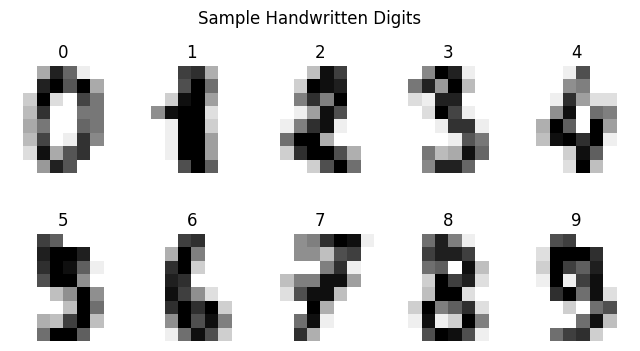

Accuracy: 0.98


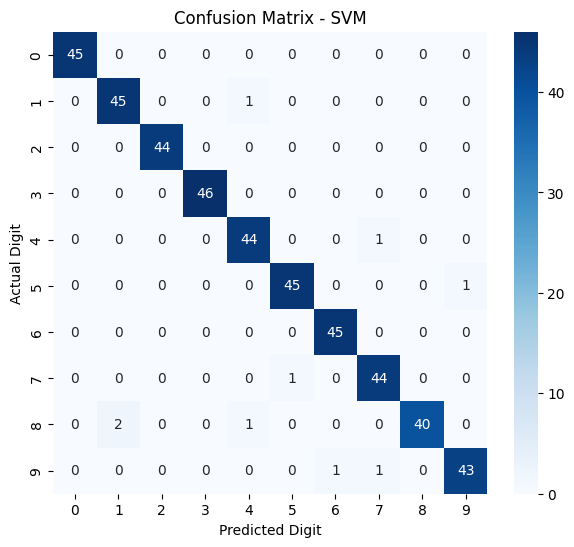

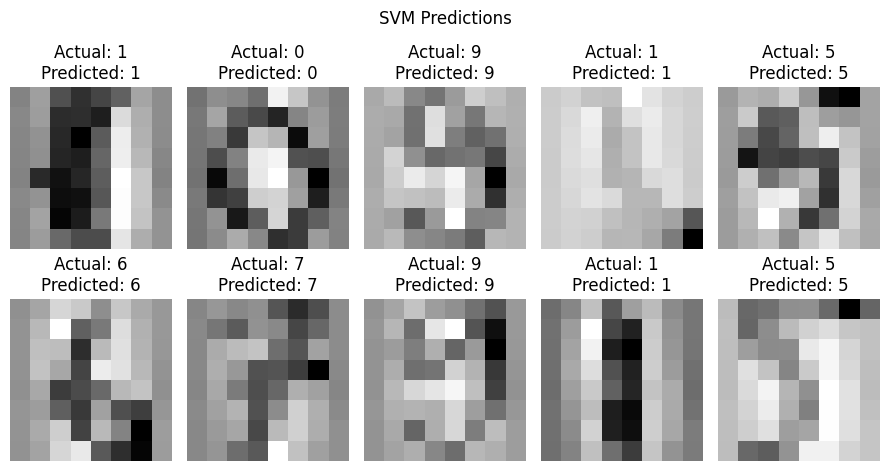

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. Load dataset
digits = load_digits()

X = digits.data
y = digits.target

print("Dataset shape:", X.shape)

# 2. Display sample images
fig, axes = plt.subplots(2, 5, figsize=(8, 4))

for ax, img, label in zip(axes.ravel(), digits.images, y):
    ax.imshow(img, cmap='gray_r')
    ax.set_title(label)
    ax.axis('off')

plt.suptitle("Sample Handwritten Digits")
plt.show()

# 3. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# 4. Scale features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 5. Train SVM model
model = SVC(kernel='rbf')
model.fit(X_train, y_train)

# 6. Predict and evaluate
y_pred = model.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

# 7. Confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("Confusion Matrix - SVM")

plt.show()

# 8. Display test images with predictions
fig, axes = plt.subplots(2, 5, figsize=(9, 5))
for ax, i in zip(axes.ravel(), range(10)):
    ax.imshow(
        X_test[i].reshape(8, 8),
        cmap='gray_r'
    )
    ax.set_title(f"Actual: {y_test[i]}\nPredicted: {y_pred[i]}")
    ax.axis('off')

plt.suptitle("SVM Predictions")
plt.tight_layout()
plt.show()